In [ ]:
import tensorflow as tf
from tensorflow.keras import layers
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
(train_images, train_labels), (_, _) = tf.keras.datasets.fashion_mnist.load_data()

print("Dataset shape:", train_images.shape)

Dataset shape: (60000, 28, 28)


In [ ]:
# reshape images
train_images = train_images.reshape(train_images.shape[0], 28, 28, 1)

# convert to float
train_images = train_images.astype('float32')

# normalize images to [-1,1]
train_images = (train_images - 127.5) / 127.5

BUFFER_SIZE = 60000
BATCH_SIZE = 256

dataset = tf.data.Dataset.from_tensor_slices(train_images)
dataset = dataset.shuffle(BUFFER_SIZE).batch(BATCH_SIZE)

In [ ]:
def build_generator():

    model = tf.keras.Sequential()

    model.add(layers.Dense(7*7*128, input_shape=(100,)))
    model.add(layers.BatchNormalization())
    model.add(layers.LeakyReLU())

    model.add(layers.Reshape((7,7,128)))

    # 7x7 → 14x14
    model.add(layers.Conv2DTranspose(64,(5,5),strides=2,padding='same'))
    model.add(layers.BatchNormalization())
    model.add(layers.LeakyReLU())

    # 14x14 → 28x28
    model.add(layers.Conv2DTranspose(1,(5,5),strides=2,padding='same',activation='tanh'))

    return model


generator = build_generator()
generator.summary()

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_2 (Dense)                 │ (None, 6272)           │       633,472 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 6272)           │        25,088 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_4 (LeakyReLU)       │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape_2 (Reshape)             │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_4              │ (None, 14, 14, 64)     │       204,864 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_5 (LeakyReLU)       │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_5              │ (None, 28, 28, 1)      │         1,601 │
│ (Conv2DTranspose)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 865,281 (3.30 MB)

 Trainable params: 852,609 (3.25 MB)

 Non-trainable params: 12,672 (49.50 KB)

In [ ]:
def build_discriminator():

    model = tf.keras.Sequential()

    model.add(layers.Conv2D(64,(5,5),strides=2,padding='same',input_shape=(28,28,1)))
    model.add(layers.LeakyReLU())
    model.add(layers.Dropout(0.3))

    model.add(layers.Conv2D(128,(5,5),strides=2,padding='same'))
    model.add(layers.LeakyReLU())
    model.add(layers.Dropout(0.3))

    model.add(layers.Flatten())
    model.add(layers.Dense(1))

    return model


discriminator = build_discriminator()
discriminator.summary()

/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 14, 14, 64)     │         1,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_6 (LeakyReLU)       │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 7, 7, 128)      │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_7 (LeakyReLU)       │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │         6,273 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 212,865 (831.50 KB)

 Trainable params: 212,865 (831.50 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
loss_function = tf.keras.losses.BinaryCrossentropy(from_logits=True)

generator_optimizer = tf.keras.optimizers.Adam(0.0001)
discriminator_optimizer = tf.keras.optimizers.Adam(0.0001)

In [ ]:
def generator_loss(fake_output):
    return loss_function(tf.ones_like(fake_output), fake_output)

def discriminator_loss(real_output, fake_output):

    real_loss = loss_function(tf.ones_like(real_output), real_output)
    fake_loss = loss_function(tf.zeros_like(fake_output), fake_output)

    return real_loss + fake_loss

In [ ]:
latent_dim = 100

def train_step(images):

    noise = tf.random.normal([images.shape[0], latent_dim])

    with tf.GradientTape() as gen_tape, tf.GradientTape() as disc_tape:

        generated_images = generator(noise, training=True)

        real_output = discriminator(images, training=True)
        fake_output = discriminator(generated_images, training=True)

        gen_loss = generator_loss(fake_output)
        disc_loss = discriminator_loss(real_output, fake_output)

    gen_gradients = gen_tape.gradient(gen_loss, generator.trainable_variables)
    disc_gradients = disc_tape.gradient(disc_loss, discriminator.trainable_variables)

    generator_optimizer.apply_gradients(zip(gen_gradients, generator.trainable_variables))
    discriminator_optimizer.apply_gradients(zip(disc_gradients, discriminator.trainable_variables))

    return gen_loss, disc_loss

In [ ]:
def generate_images(model):

    noise = tf.random.normal([16,100])
    generated_images = model(noise, training=False)

    plt.figure(figsize=(4,4))

    for i in range(16):
        plt.subplot(4,4,i+1)
        img = generated_images[i,:,:,0]*127.5 + 127.5
        plt.imshow(img, cmap='gray')
        plt.axis('off')

    plt.show()

Epoch: 1 Generator Loss: 2.7150344848632812 Discriminator Loss: 0.18907970190048218
Epoch: 2 Generator Loss: 1.4862278699874878 Discriminator Loss: 0.6973732709884644
Epoch: 3 Generator Loss: 1.2668976783752441 Discriminator Loss: 0.8461586236953735
Epoch: 4 Generator Loss: 1.0399097204208374 Discriminator Loss: 0.9633164405822754
Epoch: 5 Generator Loss: 0.9324174523353577 Discriminator Loss: 1.138206124305725


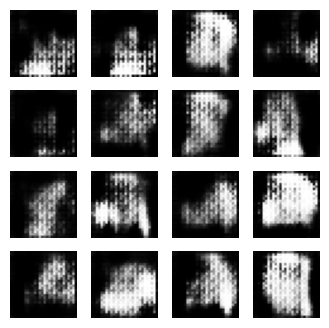

Epoch: 6 Generator Loss: 0.7199323177337646 Discriminator Loss: 1.4625808000564575
Epoch: 7 Generator Loss: 0.83056640625 Discriminator Loss: 1.2058861255645752
Epoch: 8 Generator Loss: 0.8421024680137634 Discriminator Loss: 1.3217723369598389
Epoch: 9 Generator Loss: 0.6924688220024109 Discriminator Loss: 1.4791306257247925
Epoch: 10 Generator Loss: 0.7629496455192566 Discriminator Loss: 1.2953052520751953


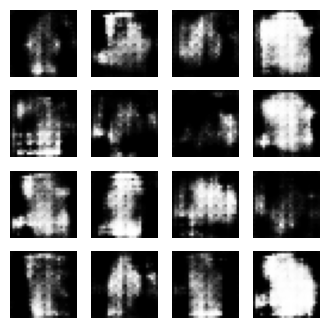

Epoch: 11 Generator Loss: 1.0361099243164062 Discriminator Loss: 1.0888205766677856
Epoch: 12 Generator Loss: 0.790971577167511 Discriminator Loss: 1.4474239349365234
Epoch: 13 Generator Loss: 0.9783373475074768 Discriminator Loss: 1.1426975727081299
Epoch: 14 Generator Loss: 1.1702086925506592 Discriminator Loss: 1.0333857536315918
Epoch: 15 Generator Loss: 1.0444412231445312 Discriminator Loss: 1.133183240890503


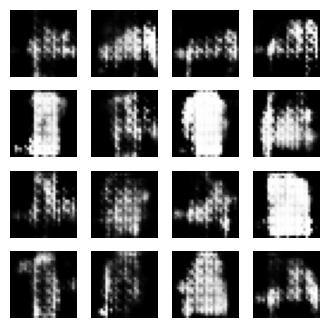

Epoch: 16 Generator Loss: 1.0755805969238281 Discriminator Loss: 1.1080052852630615
Epoch: 17 Generator Loss: 1.284058928489685 Discriminator Loss: 0.8803979158401489
Epoch: 18 Generator Loss: 1.3491493463516235 Discriminator Loss: 0.8565454483032227
Epoch: 19 Generator Loss: 1.073006272315979 Discriminator Loss: 1.0523972511291504
Epoch: 20 Generator Loss: 1.198065996170044 Discriminator Loss: 0.9717891216278076


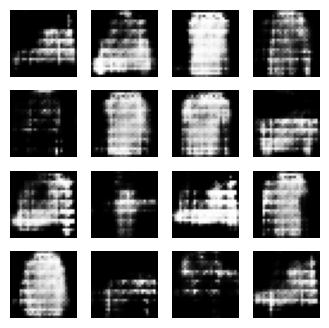

Epoch: 21 Generator Loss: 1.188922643661499 Discriminator Loss: 1.0215704441070557
Epoch: 22 Generator Loss: 1.147447109222412 Discriminator Loss: 1.0191881656646729
Epoch: 23 Generator Loss: 1.3474241495132446 Discriminator Loss: 0.9305610060691833
Epoch: 24 Generator Loss: 1.3500016927719116 Discriminator Loss: 0.9298743009567261
Epoch: 25 Generator Loss: 1.258644461631775 Discriminator Loss: 1.1366844177246094


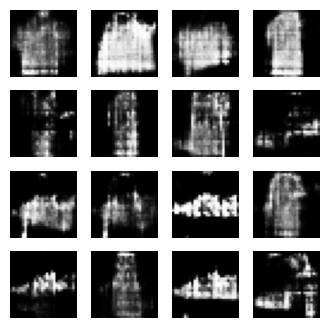

Epoch: 26 Generator Loss: 1.3145486116409302 Discriminator Loss: 1.1076838970184326
Epoch: 27 Generator Loss: 1.315303921699524 Discriminator Loss: 1.0058174133300781
Epoch: 28 Generator Loss: 1.304559588432312 Discriminator Loss: 1.0996766090393066
Epoch: 29 Generator Loss: 1.461548924446106 Discriminator Loss: 0.7573630213737488
Epoch: 30 Generator Loss: 1.4948577880859375 Discriminator Loss: 0.9060375690460205


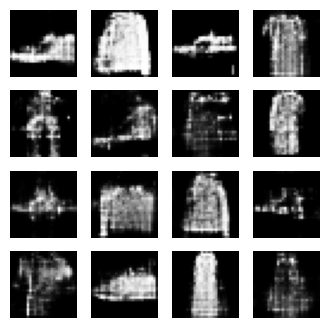

In [ ]:
EPOCHS = 30

g_losses = []
d_losses = []

for epoch in range(EPOCHS):

    for image_batch in dataset:

        g_loss, d_loss = train_step(image_batch)

    g_losses.append(g_loss)
    d_losses.append(d_loss)

    print("Epoch:", epoch+1,
          "Generator Loss:", float(g_loss),
          "Discriminator Loss:", float(d_loss))

    if (epoch+1) % 5 == 0:
        generate_images(generator)

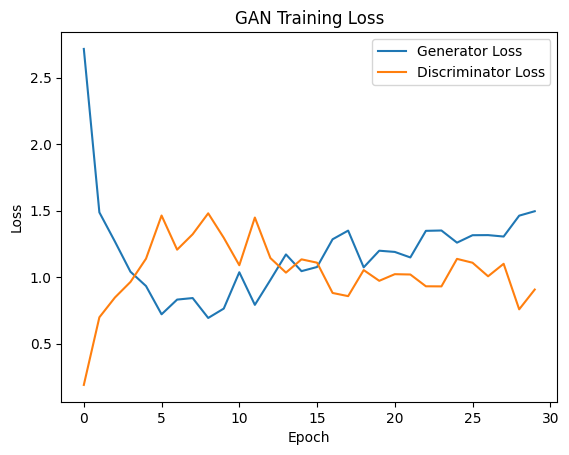

In [ ]:
plt.plot(g_losses,label="Generator Loss")
plt.plot(d_losses,label="Discriminator Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("GAN Training Loss")
plt.legend()

plt.show()